In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

SEED = 42
LABELS = ["Low", "Mid", "High"]
LABEL_MAP = {"Low": 0, "Mid": 1, "High": 2}
PROB_COLS = ["p_Low", "p_Mid", "p_High"]

# Tìm thư mục output
cwd = Path.cwd()

if (cwd / "splits" / "test.csv").exists():
    BASE = cwd
elif (cwd / "output" / "splits" / "test.csv").exists():
    BASE = cwd / "output"
else:
    raise FileNotFoundError("Không tìm thấy thư mục splits.")

RESULT_DIR = BASE / "section_4_3"
RESULT_DIR.mkdir(parents=True, exist_ok=True)


def load_split_with_probs(split_name):
    actual = pd.read_csv(
        BASE / "splits" / f"{split_name}.csv"
    )

    probabilities = pd.read_csv(
        BASE / "section_4_2"
        / f"full_{split_name}_probs.csv"
    )

    assert actual["row_id"].is_unique
    assert probabilities["row_id"].is_unique

    assert set(actual["row_id"]) == set(
        probabilities["row_id"]
    ), f"Không khớp row_id: {split_name}"

    merged = actual[["row_id", "RiskLevel"]].merge(
        probabilities[["row_id"] + PROB_COLS],
        on="row_id",
        how="inner",
        validate="one_to_one"
    )

    p = merged[PROB_COLS].to_numpy(dtype=float)

    assert np.isfinite(p).all()
    assert np.all((p >= 0) & (p <= 1))
    assert np.allclose(p.sum(axis=1), 1, atol=1e-6)

    y = merged["RiskLevel"].map(LABEL_MAP)

    assert y.notna().all()

    return merged, y.to_numpy(dtype=int), p


val_df, y_val, p_val = load_split_with_probs(
    "policy_val"
)

test_df, y_test, p_test = load_split_with_probs(
    "test"
)

print("Policy Validation:", len(val_df))
print("Test:", len(test_df))
print("Model: Full XGBoost — calibrated probabilities")
print("READY FOR SEVERITY ANALYSIS!")


Policy Validation: 606
Test: 1212
Model: Full XGBoost — calibrated probabilities
READY FOR SEVERITY ANALYSIS!


In [2]:

def make_cost_matrix(undertriage_weight=1.0):
    """
    Rows:    True class (Low, Mid, High)
    Columns: Predicted class (Low, Mid, High)

    All costs are hypothetical penalty units.
    """
    C = np.zeros((3, 3), dtype=float)

    for true_class in range(3):
        for predicted_class in range(3):

            distance = abs(
                true_class - predicted_class
            )

            if predicted_class < true_class:
                C[true_class, predicted_class] = (
                    distance * undertriage_weight
                )
            else:
                C[true_class, predicted_class] = distance

    return C


# Reference cost matrix — dùng chung để đánh giá
REFERENCE_LAMBDA = 3.0
C_REFERENCE = make_cost_matrix(REFERENCE_LAMBDA)

print("Reference Cost Matrix:")
display(
    pd.DataFrame(
        C_REFERENCE,
        index=["Actual Low", "Actual Mid", "Actual High"],
        columns=["Predict Low", "Predict Mid", "Predict High"]
    )
)


Reference Cost Matrix:


,Predict Low,Predict Mid,Predict High
Actual Low,0.0,1.0,2.0
Actual Mid,3.0,0.0,1.0
Actual High,6.0,3.0,0.0


In [3]:

POLICIES = [
    {"name": "Argmax", "type": "argmax", "lambda": None},
    {"name": "Ordinal", "type": "cost", "lambda": 1.0},
    {"name": "Asym-2", "type": "cost", "lambda": 2.0},
    {"name": "Asym-3", "type": "cost", "lambda": 3.0},
    {"name": "Asym-5", "type": "cost", "lambda": 5.0},
    {"name": "Asym-10", "type": "cost", "lambda": 10.0},
    {"name": "Asym-20", "type": "cost", "lambda": 20.0}
]


def predict_with_policy(probs, policy):
    probs = np.asarray(probs, dtype=float)

    if policy["type"] == "argmax":
        return np.argmax(probs, axis=1)

    C = make_cost_matrix(policy["lambda"])

    # ExpectedCost[n, predicted_class]
    # = sum over possible true classes:
    # P(true_class) * Cost(true_class, predicted_class)
    expected_cost = probs @ C

    return np.argmin(expected_cost, axis=1)


# Ví dụ minh họa
example_prob = np.array([
    [0.20, 0.45, 0.35]
])

for policy in POLICIES:
    predicted = predict_with_policy(
        example_prob, policy
    )[0]

    print(
        f"{policy['name']:10s} -> "
        f"{LABELS[predicted]}"
    )


Argmax     -> Mid
Ordinal    -> Mid
Asym-2     -> High
Asym-3     -> High
Asym-5     -> High
Asym-10    -> High
Asym-20    -> High


In [4]:

def evaluate_severity(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    n = len(y_true)

    wrong = y_true != y_pred

    under = y_pred < y_true
    over = y_pred > y_true

    severe = np.abs(y_true - y_pred) == 2

    high_to_low = (
        (y_true == 2) & (y_pred == 0)
    )

    high_to_mid = (
        (y_true == 2) & (y_pred == 1)
    )

    observed_cost = C_REFERENCE[y_true, y_pred]

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro_F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "High_Risk_Recall": recall_score(
            y_true, y_pred,
            labels=[2],
            average="macro",
            zero_division=0
        ),

        "Ordinal_MAE": float(
            np.mean(np.abs(y_true - y_pred))
        ),

        "Total_Errors": int(wrong.sum()),
        "Undertriage": int(under.sum()),
        "Overtriage": int(over.sum()),

        "Severe_Errors": int(severe.sum()),
        "Severe_Error_Rate": 100 * severe.mean(),

        "High_to_Low": int(high_to_low.sum()),
        "High_to_Mid": int(high_to_mid.sum()),

        # Cùng một thang phạt cho mọi policy
        "Reference_Cost_per_100": float(
            observed_cost.mean() * 100
        )
    }


# Baseline trên Policy Validation
baseline_val = predict_with_policy(
    p_val, POLICIES[0]
)

baseline_metrics = evaluate_severity(
    y_val, baseline_val
)

display(
    pd.DataFrame([baseline_metrics]).round(5)
)


,Accuracy,Macro_F1,High_Risk_Recall,Ordinal_MAE,Total_Errors,Undertriage,Overtriage,Severe_Errors,Severe_Error_Rate,High_to_Low,High_to_Mid,Reference_Cost_per_100
0,0.9868,0.9868,0.97015,0.0165,8,6,2,2,0.33003,2,4,4.29043


In [5]:

validation_results = []
validation_predictions = {}

for policy in POLICIES:
    name = policy["name"]

    predicted = predict_with_policy(
        p_val, policy
    )

    validation_predictions[name] = predicted

    metrics = evaluate_severity(
        y_val, predicted
    )

    validation_results.append({
        "Policy": name,
        "Lambda": (
            policy["lambda"]
            if policy["lambda"] is not None
            else 0.0
        ),
        **metrics
    })

validation_table = pd.DataFrame(
    validation_results
)

columns = [
    "Policy",
    "Macro_F1",
    "High_Risk_Recall",
    "Ordinal_MAE",
    "Total_Errors",
    "Undertriage",
    "Overtriage",
    "Severe_Errors",
    "High_to_Low",
    "Reference_Cost_per_100"
]

display(
    validation_table[columns].round(5)
)

validation_table.to_csv(
    RESULT_DIR / "validation_policy_comparison.csv",
    index=False
)

print("POLICY VALIDATION COMPLETED!")


,Policy,Macro_F1,High_Risk_Recall,Ordinal_MAE,Total_Errors,Undertriage,Overtriage,Severe_Errors,High_to_Low,Reference_Cost_per_100
0,Argmax,0.98680,0.97015,0.01650,8,6,2,2,2,4.29043
1,Ordinal,0.98515,0.96517,0.01815,9,7,2,2,2,4.78548
2,Asym-2,0.98516,0.97015,0.01815,9,6,3,2,2,4.45545
3,Asym-3,0.98684,0.97512,0.01485,8,5,3,1,1,3.46535
4,Asym-5,0.98519,0.97512,0.01650,9,5,4,1,1,3.63036
5,Asym-10,0.98356,0.97512,0.01815,10,5,5,1,1,3.79538
6,Asym-20,0.98033,0.98010,0.01980,12,4,8,0,0,3.30033


POLICY VALIDATION COMPLETED!


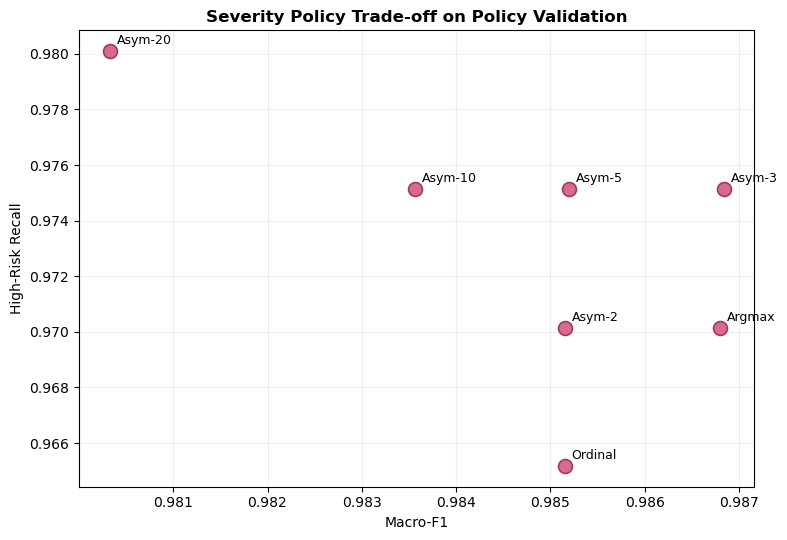

In [6]:

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    validation_table["Macro_F1"],
    validation_table["High_Risk_Recall"],
    s=100,
    color="#D86A8A",
    edgecolor="#9F3A5B",
    linewidth=1.2,
    zorder=3
)

for _, row in validation_table.iterrows():
    ax.annotate(
        row["Policy"],
        (
            row["Macro_F1"],
            row["High_Risk_Recall"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Macro-F1")
ax.set_ylabel("High-Risk Recall")
ax.set_title(
    "Severity Policy Trade-off on Policy Validation",
    fontweight="bold"
)
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "severity_tradeoff_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

# Fixed policy-selection settings
MAX_MACRO_F1_DROP = 0.01

base_f1 = float(
    validation_table.loc[
        validation_table["Policy"] == "Argmax",
        "Macro_F1"
    ].iloc[0]
)

minimum_allowed_f1 = (
    base_f1 - MAX_MACRO_F1_DROP
)

eligible = validation_table[
    validation_table["Macro_F1"]
    >= minimum_allowed_f1 - 1e-12
].copy()

assert len(eligible) > 0

eligible = eligible.sort_values(
    [
        "Reference_Cost_per_100",
        "High_Risk_Recall",
        "Macro_F1",
        "Lambda"
    ],
    ascending=[True, False, False, True],
    kind="mergesort"
)

selected_name = eligible.iloc[0]["Policy"]

selected_policy = next(
    p for p in POLICIES
    if p["name"] == selected_name
)

print("Baseline Validation Macro-F1:", round(base_f1, 5))
print("Minimum allowed Macro-F1:",
      round(minimum_allowed_f1, 5))

print("\nELIGIBLE POLICIES:")
display(
    eligible[columns].round(5)
)

print("\nSELECTED POLICY:", selected_name)

# Lưu chính sách để Giang dùng ở Section 5
selection_metadata = {
    "section": "4.3 Severity-Aware Classification",
    "model": "Full XGBoost",
    "probability_source": "Section 4.2 calibrated probabilities",
    "selection_split": "policy_val",
    "selected_policy": selected_policy,
    "reference_lambda": REFERENCE_LAMBDA,
    "reference_cost_matrix": C_REFERENCE.tolist(),
    "max_macro_f1_drop": MAX_MACRO_F1_DROP,
    "selection_metric": "Fixed reference cost per 100",
    "selection_tiebreakers": [
        "High-Risk Recall (descending)",
        "Macro-F1 (descending)",
        "Lambda (ascending)"
    ],
    "risk_class_order": LABELS
}

with open(
    RESULT_DIR / "selected_severity_policy.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        selection_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nSEVERITY POLICY LOCKED!")


Baseline Validation Macro-F1: 0.9868
Minimum allowed Macro-F1: 0.9768

ELIGIBLE POLICIES:


,Policy,Macro_F1,High_Risk_Recall,Ordinal_MAE,Total_Errors,Undertriage,Overtriage,Severe_Errors,High_to_Low,Reference_Cost_per_100
6,Asym-20,0.98033,0.98010,0.01980,12,4,8,0,0,3.30033
3,Asym-3,0.98684,0.97512,0.01485,8,5,3,1,1,3.46535
4,Asym-5,0.98519,0.97512,0.01650,9,5,4,1,1,3.63036
5,Asym-10,0.98356,0.97512,0.01815,10,5,5,1,1,3.79538
0,Argmax,0.98680,0.97015,0.01650,8,6,2,2,2,4.29043
2,Asym-2,0.98516,0.97015,0.01815,9,6,3,2,2,4.45545
1,Ordinal,0.98515,0.96517,0.01815,9,7,2,2,2,4.78548



SELECTED POLICY: Asym-20

SEVERITY POLICY LOCKED!


In [10]:

# Ba phương án cần so sánh
comparison_names = [
    "Argmax",
    "Ordinal",
    selected_name
]

# Không lặp nếu selected = Argmax hoặc Ordinal
comparison_names = list(
    dict.fromkeys(comparison_names)
)

test_results = []
test_predictions = {}

for name in comparison_names:
    policy = next(
        p for p in POLICIES
        if p["name"] == name
    )

    predicted = predict_with_policy(
        p_test, policy
    )

    test_predictions[name] = predicted

    metrics = evaluate_severity(
        y_test, predicted
    )

    test_results.append({
        "Policy": name,
        **metrics
    })

test_table = pd.DataFrame(test_results)

display(
    test_table[columns[:1] + columns[2:]].round(5)
)

test_table.to_csv(
    RESULT_DIR / "test_severity_comparison.csv",
    index=False
)

print("TEST EVALUATION COMPLETED!")

,Policy,High_Risk_Recall,Ordinal_MAE,Total_Errors,Undertriage,Overtriage,Severe_Errors,High_to_Low,Reference_Cost_per_100
0,Argmax,0.99007,0.0066,7,6,1,1,1,1.81518
1,Ordinal,0.99007,0.0066,7,6,1,1,1,1.81518
2,Asym-20,0.99752,0.0198,24,3,21,0,0,2.47525


TEST EVALUATION COMPLETED!


In [11]:
selected_cm = confusion_matrix(
    y_test,
    selected_pred,
    labels=[0, 1, 2]
)


fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
selected_cm,
cmap="RdPu"
)

ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)

ax.set_xlabel("Predicted Risk Level")
ax.set_ylabel("Actual Risk Level")

ax.set_title(
f"Severity-Aware Classification — {selected_name}",
fontweight="bold"
)

max_count = selected_cm.max()

for i in range(3):
for j in range(3):
value = selected_cm[i, j]

color = (
"white"
if value > max_count / 2
else "#333333"
)

ax.text(
j, i, str(value),
ha="center",
va="center",
color=color,
fontsize=12,
fontweight="bold"
)

plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

plt.savefig(
RESULT_DIR / "severity_confusion_matrix.png",
dpi=300,
bbox_inches="tight"
)

plt.show()

IndentationError: expected an indented block after 'for' statement on line 28 (3616813898.py, line 29)

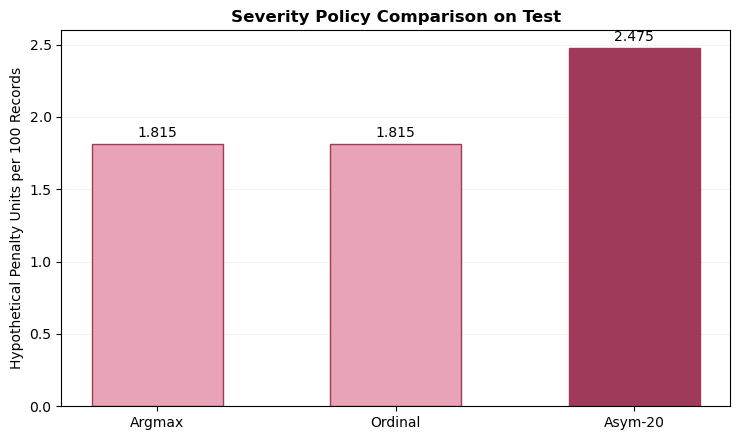

In [12]:

plot_df = test_table.copy()

fig, ax = plt.subplots(figsize=(7.5, 4.5))

colors = [
    "#E9A3B7" if p != selected_name else "#9F3A5B"
    for p in plot_df["Policy"]
]

bars = ax.bar(
    plot_df["Policy"],
    plot_df["Reference_Cost_per_100"],
    color=colors,
    edgecolor="#9F3A5B",
    width=0.55
)

for bar in bars:
    value = bar.get_height()

    ax.annotate(
        f"{value:.3f}",
        (
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_ylabel(
    "Hypothetical Penalty Units per 100 Records"
)

ax.set_title(
    "Severity Policy Comparison on Test",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "severity_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

rng = np.random.default_rng(SEED)

base_cost = C_REFERENCE[
    y_test, base_pred
]

selected_cost = C_REFERENCE[
    y_test, selected_pred
]

# Positive difference = severity policy has lower cost
cost_improvement_each = (
    base_cost - selected_cost
)

observed_improvement = (
    cost_improvement_each.mean() * 100
)

N_BOOTSTRAP = 2000
bootstrap_values = []

n = len(y_test)

for _ in range(N_BOOTSTRAP):
    sampled_idx = rng.integers(
        0, n, size=n
    )

    improvement = (
        cost_improvement_each[sampled_idx].mean()
        * 100
    )

    bootstrap_values.append(improvement)

ci_low, ci_high = np.percentile(
    bootstrap_values,
    [2.5, 97.5]
)

print("Selected policy:", selected_name)

print(
    "Observed reduction in penalty units per 100:",
    round(observed_improvement, 5)
)

print(
    "95% Bootstrap Interval:",
    f"[{ci_low:.5f}, {ci_high:.5f}]"
)

bootstrap_summary = pd.DataFrame([{
    "Policy": selected_name,
    "Cost_Improvement_Per_100": observed_improvement,
    "CI_2_5": ci_low,
    "CI_97_5": ci_high,
    "Bootstrap_Resamples": N_BOOTSTRAP
}])

bootstrap_summary.to_csv(
    RESULT_DIR / "bootstrap_cost_comparison.csv",
    index=False
)


NameError: name 'base_pred' is not defined

In [14]:

sensitivity_rows = []

for reference_weight in [2.0, 3.0, 5.0]:
    C_ref = make_cost_matrix(reference_weight)

    for policy in POLICIES:
        pred = validation_predictions[policy["name"]]

        observed_cost = (
            C_ref[y_val, pred].mean() * 100
        )

        sensitivity_rows.append({
            "Reference_Lambda": reference_weight,
            "Policy": policy["name"],
            "Cost_per_100": observed_cost
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)

pivot = sensitivity_df.pivot(
    index="Policy",
    columns="Reference_Lambda",
    values="Cost_per_100"
)

display(pivot.round(4))

sensitivity_df.to_csv(
    RESULT_DIR / "cost_sensitivity_validation.csv",
    index=False
)


Reference_Lambda,2.0,3.0,5.0
Policy,,,
Argmax,2.9703,4.2904,6.9307
Asym-10,2.8053,3.7954,5.7756
Asym-2,3.1353,4.4554,7.0957
Asym-20,2.6403,3.3003,4.6205
Asym-3,2.4752,3.4653,5.4455
Asym-5,2.6403,3.6304,5.6106
Ordinal,3.3003,4.7855,7.7558


In [15]:
base_pred = test_predictions["Argmax"]
severity_pred = test_predictions["Asym-20"]

changed = base_pred != severity_pred

print("Changed decisions:", changed.sum())

transition = pd.crosstab(
    pd.Series(np.array(LABELS)[base_pred[changed]],
              name="Argmax"),
    pd.Series(np.array(LABELS)[severity_pred[changed]],
              name="Asym-20")
)

display(transition)

Changed decisions: 23


Asym-20,High,Mid
Argmax,,
Low,1,4
Mid,18,0


In [16]:

# CELL 15 — Decision Change Audit

import numpy as np
import pandas as pd

base_pred = test_predictions["Argmax"]
severity_pred = test_predictions["Asym-20"]

changed = base_pred != severity_pred

audit = pd.DataFrame({
    "row_id": test_df["row_id"].to_numpy(),
    "Actual": np.array(LABELS)[y_test],
    "Argmax": np.array(LABELS)[base_pred],
    "Asym20": np.array(LABELS)[severity_pred],
    "Actual_Code": y_test,
    "Argmax_Code": base_pred,
    "Asym20_Code": severity_pred
})

audit = audit.loc[changed].copy()

audit["Before_Correct"] = (
    audit["Actual_Code"] == audit["Argmax_Code"]
)

audit["After_Correct"] = (
    audit["Actual_Code"] == audit["Asym20_Code"]
)

audit["Outcome"] = np.select(
    [
        (~audit["Before_Correct"]) & audit["After_Correct"],
        audit["Before_Correct"] & (~audit["After_Correct"]),
        (~audit["Before_Correct"]) & (~audit["After_Correct"])
    ],
    [
        "Corrected Error",
        "New Error",
        "Still Incorrect"
    ],
    default="Other"
)

print("Changed decisions:", len(audit))

print("\nOUTCOME OF CHANGES:")
display(audit["Outcome"].value_counts().rename_axis(
    "Outcome"
).reset_index(name="Records"))

print("\nACTUAL CLASS × TRANSITION:")
display(
    pd.crosstab(
        [audit["Argmax"], audit["Asym20"]],
        audit["Actual"]
    )
)

display(
    audit[
        ["row_id", "Actual", "Argmax",
         "Asym20", "Outcome"]
    ]
)

audit.to_csv(
    RESULT_DIR / "decision_change_audit.csv",
    index=False
)


Changed decisions: 23

OUTCOME OF CHANGES:


,Outcome,Records
0,New Error,20
1,Corrected Error,3



ACTUAL CLASS × TRANSITION:


Actual         High  Low  Mid
Argmax Asym20                
Low    High       1    0    0
       Mid        0    4    0
Mid    High       2    0   16

,row_id,Actual,Argmax,Asym20,Outcome
27,R000122,Mid,Mid,High,New Error
115,R000568,Low,Low,Mid,New Error
126,R000623,Mid,Mid,High,New Error
130,R000674,Mid,Mid,High,New Error
223,R001093,High,Mid,High,Corrected Error
224,R001099,Mid,Mid,High,New Error
244,R001233,Mid,Mid,High,New Error
266,R001330,Mid,Mid,High,New Error
282,R001431,Mid,Mid,High,New Error
327,R001667,Low,Low,Mid,New Error


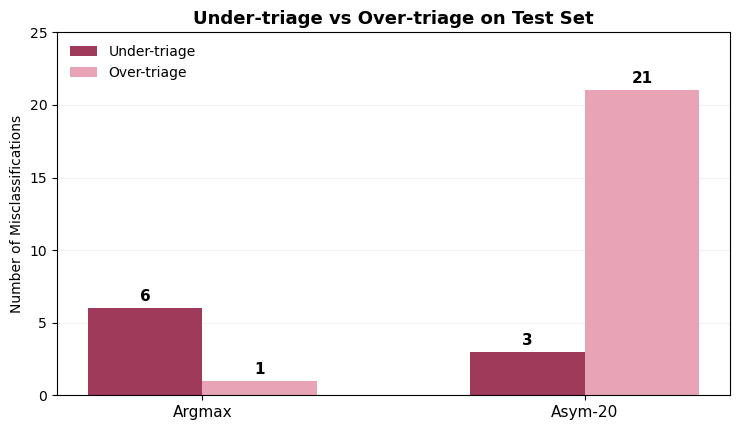

In [17]:

# CELL 16 — Severity Trade-off Figure

import matplotlib.pyplot as plt
import numpy as np

policies = ["Argmax", "Asym-20"]

undertriage = [6, 3]
overtriage = [1, 21]

x = np.arange(len(policies))
width = 0.30

fig, ax = plt.subplots(figsize=(7.5, 4.4))

bars1 = ax.bar(
    x - width/2,
    undertriage,
    width,
    label="Under-triage",
    color="#9F3A5B"
)

bars2 = ax.bar(
    x + width/2,
    overtriage,
    width,
    label="Over-triage",
    color="#E9A3B7"
)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            str(int(h)),
            (
                bar.get_x() + bar.get_width()/2,
                h
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

ax.set_xticks(x)
ax.set_xticklabels(policies, fontsize=11)

ax.set_ylabel("Number of Misclassifications")
ax.set_title(
    "Under-triage vs Over-triage on Test Set",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(0, 25)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "severity_error_direction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


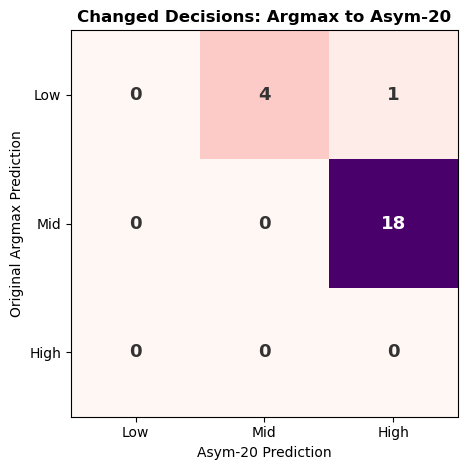

In [18]:

# CELL 17 — Decision Transition Heatmap

import numpy as np
import matplotlib.pyplot as plt

transition_matrix = np.zeros((3, 3), dtype=int)

for before, after in zip(
    base_pred[changed],
    severity_pred[changed]
):
    transition_matrix[before, after] += 1

fig, ax = plt.subplots(figsize=(6, 4.8))

im = ax.imshow(
    transition_matrix,
    cmap="RdPu",
    vmin=0,
    vmax=max(1, transition_matrix.max())
)

for i in range(3):
    for j in range(3):
        value = transition_matrix[i, j]

        ax.text(
            j, i, str(value),
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color=(
                "white" if value > 9
                else "#333333"
            )
        )

ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)

ax.set_xlabel("Asym-20 Prediction")
ax.set_ylabel("Original Argmax Prediction")

ax.set_title(
    "Changed Decisions: Argmax to Asym-20",
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "severity_decision_transitions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# CELL 13 — Paired Bootstrap Cost Comparison
# Argmax vs Validation-Selected Severity Policy

import numpy as np
import pandas as pd

SEED = 42
N_BOOTSTRAP = 2000

rng = np.random.default_rng(SEED)

# 1. Lấy dự đoán đã tạo ở Cell 8
base_pred = np.asarray(
    test_predictions["Argmax"],
    dtype=int
)

selected_pred = np.asarray(
    test_predictions[selected_name],
    dtype=int
)

y = np.asarray(y_test, dtype=int)

assert len(y) == len(base_pred) == len(selected_pred)

print("Selected policy:", selected_name)
print("Test records:", len(y))

# 2. Chi phí giả định cho từng record
base_cost = C_REFERENCE[y, base_pred]
selected_cost = C_REFERENCE[y, selected_pred]

# Số dương = Severity Policy tốt hơn Argmax
# Số âm = Severity Policy tốn chi phí hơn
cost_improvement_each = base_cost - selected_cost

observed_improvement = (
    cost_improvement_each.mean() * 100
)

# 3. Paired bootstrap: giữ nguyên cặp dự đoán
bootstrap_values = np.empty(N_BOOTSTRAP)

n = len(y)

for i in range(N_BOOTSTRAP):
    sampled_idx = rng.integers(
        0, n, size=n
    )

    bootstrap_values[i] = (
        cost_improvement_each[sampled_idx].mean()
        * 100
    )

# 4. 95% percentile confidence interval
ci_low, ci_high = np.percentile(
    bootstrap_values,
    [2.5, 97.5]
)

# 5. Hiển thị kết quả
print("\n===== BOOTSTRAP RESULTS =====")

print(
    "Argmax reference cost / 100:",
    round(base_cost.mean() * 100, 5)
)

print(
    f"{selected_name} reference cost / 100:",
    round(selected_cost.mean() * 100, 5)
)

print(
    "Cost improvement / 100:",
    round(observed_improvement, 5)
)

print(
    "95% Bootstrap CI:",
    f"[{ci_low:.5f}, {ci_high:.5f}]"
)

print(
    "CI includes zero:",
    bool(ci_low <= 0 <= ci_high)
)

# 6. Lưu kết quả
bootstrap_summary = pd.DataFrame([{
    "Policy": selected_name,
    "Argmax_Cost_Per_100": base_cost.mean() * 100,
    "Selected_Cost_Per_100": selected_cost.mean() * 100,
    "Cost_Improvement_Per_100": observed_improvement,
    "CI_2_5": ci_low,
    "CI_97_5": ci_high,
    "Bootstrap_Resamples": N_BOOTSTRAP
}])

display(bootstrap_summary.round(5))

bootstrap_summary.to_csv(
    RESULT_DIR / "bootstrap_cost_comparison.csv",
    index=False
)

print("\nBOOTSTRAP COMPLETED!")


Selected policy: Asym-20
Test records: 1212

===== BOOTSTRAP RESULTS =====
Argmax reference cost / 100: 1.81518
Asym-20 reference cost / 100: 2.47525
Cost improvement / 100: -0.66007
95% Bootstrap CI: [-1.89769, 0.82508]
CI includes zero: True


,Policy,Argmax_Cost_Per_100,Selected_Cost_Per_100,Cost_Improvement_Per_100,CI_2_5,CI_97_5,Bootstrap_Resamples
0,Asym-20,1.81518,2.47525,-0.66007,-1.89769,0.82508,2000



BOOTSTRAP COMPLETED!


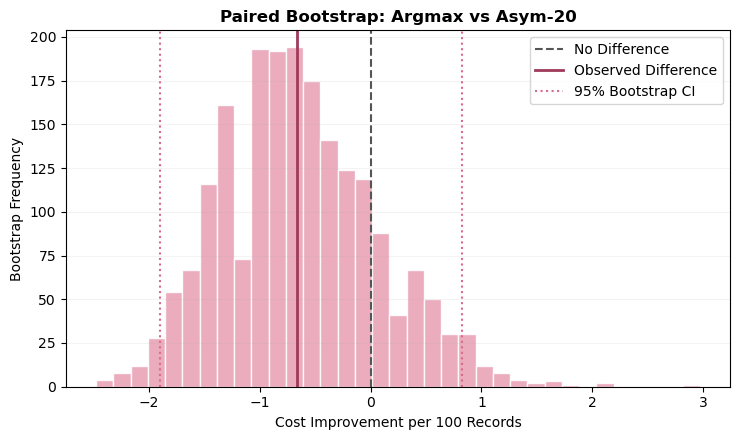

In [21]:

# CELL 13B — Bootstrap Distribution

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.hist(
    bootstrap_values,
    bins=35,
    color="#E9A3B7",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    0,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label="No Difference"
)

ax.axvline(
    observed_improvement,
    color="#9F3A5B",
    linewidth=2,
    label="Observed Difference"
)

ax.axvline(
    ci_low,
    color="#D86A8A",
    linestyle=":",
    linewidth=1.5
)

ax.axvline(
    ci_high,
    color="#D86A8A",
    linestyle=":",
    linewidth=1.5,
    label="95% Bootstrap CI"
)

ax.set_xlabel(
    "Cost Improvement per 100 Records"
)

ax.set_ylabel("Bootstrap Frequency")

ax.set_title(
    "Paired Bootstrap: Argmax vs Asym-20",
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.15)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "bootstrap_cost_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
